# 03 · Clasificación de imágenes en CIFAR-10: CPU frente a GPU

**Curso:** Fundamentos de Programación para la Inteligencia Artificial · **Autor:** William Lu Bjornestad

---

Primer problema de **clasificación** del curso, con un conjunto de datos real: CIFAR-10 (60 000 imágenes a color de $32 \times 32$ en 10 clases). Se entrena un MLP y se compara el tiempo de entrenamiento en CPU y en GPU. Al separar los factores que intervienen en esa comparación, se ve que el **pipeline de datos** pesa tanto como el hardware.

**Objetivos**

- Entrenar un clasificador con parada temprana (*early stopping*).
- Medir de forma justa la aceleración que aporta la GPU.
- Evaluar el modelo con matriz de confusión y métricas por clase.

**Conceptos de pipeline de ML introducidos**

| Etapa | Qué se ve en este cuaderno |
|---|---|
| Transformaciones encadenadas | `transforms.Compose` con normalización por canal |
| Código independiente del dispositivo | El mismo bucle funciona en CPU y en GPU |
| Carga de datos eficiente | Precálculo de tensores, precarga en GPU y *batching* en dispositivo |
| *Early stopping* | Parada automática y restauración de los mejores pesos |
| Métricas de clasificación | Exactitud, matriz de confusión, precisión / recall / F1 por clase |
| Persistencia | Guardar el modelo **junto con** su preprocesado |

In [1]:
import copy
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

SEED = 42
torch.manual_seed(SEED)
DATA_DIR = "../data"
CKPT_DIR = Path("../checkpoints")
CKPT_DIR.mkdir(exist_ok=True)

gpu = torch.device("cuda") if torch.cuda.is_available() else None
cpu = torch.device("cpu")
print("GPU disponible:", torch.cuda.get_device_name(0) if gpu else "no")

CLASSES = ["avión", "automóvil", "pájaro", "gato", "ciervo", "perro", "rana", "caballo", "barco", "camión"]

GPU disponible: NVIDIA GeForce RTX 2050


## 1. Datos y preprocesado

Las imágenes se normalizan **por canal** con la media y la desviación típica del conjunto de entrenamiento: $x' = (x - \mu_c)/\sigma_c$. Es la versión para imágenes de la estandarización del cuaderno 01, y las estadísticas se calculan igualmente solo con train.

`transforms.Compose` encadena las transformaciones en un único objeto reutilizable: convertir a tensor en $[0, 1]$ y después normalizar.

In [2]:
raw_train = datasets.CIFAR10(DATA_DIR, train=True, download=True)
channel_mean = (raw_train.data / 255.0).mean(axis=(0, 1, 2))
channel_std = (raw_train.data / 255.0).std(axis=(0, 1, 2))
print("Media por canal:", channel_mean.round(4), "| Desviación por canal:", channel_std.round(4))

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(channel_mean.tolist(), channel_std.tolist()),
])

train_set = datasets.CIFAR10(DATA_DIR, train=True, transform=preprocess)
test_full = datasets.CIFAR10(DATA_DIR, train=False, transform=preprocess)

Files already downloaded and verified


Media por canal: [0.4914 0.4822 0.4465] | Desviación por canal: [0.247  0.2435 0.2616]


El conjunto de test oficial (10 000 imágenes) se divide a partes iguales en **validación** y **test**. `random_split` con un generador con semilla hace la partición reproducible y solo baraja índices, sin necesidad de cargar cada imagen para decidir a qué subconjunto va.

Entrenamiento: 50000 | validación: 5000 | test: 5000


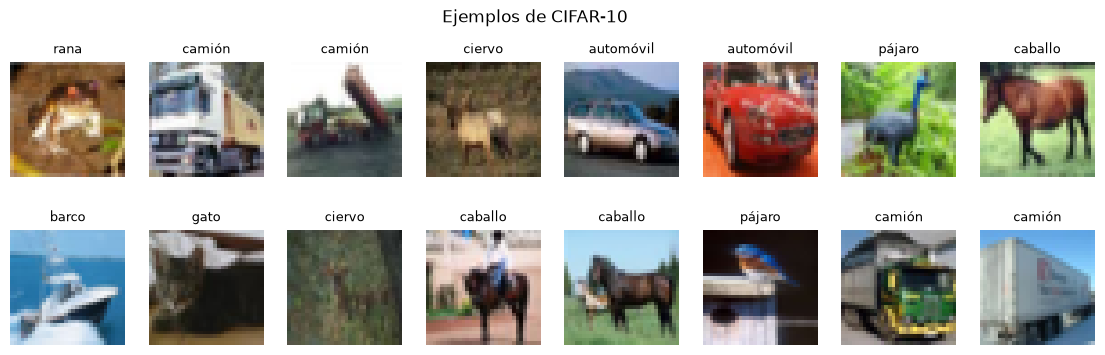

In [3]:
val_set, test_set = random_split(test_full, [5000, 5000], generator=torch.Generator().manual_seed(SEED))
print(f"Entrenamiento: {len(train_set)} | validación: {len(val_set)} | test: {len(test_set)}")

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, idx in zip(axes.flat, range(16)):
    img, label = raw_train[idx]
    ax.imshow(img)
    ax.set_title(CLASSES[label], fontsize=9)
    ax.axis("off")
plt.suptitle("Ejemplos de CIFAR-10")
plt.show()

Como estas transformaciones son **deterministas** (siempre dan el mismo resultado para la misma imagen), basta con aplicarlas una vez y guardar el resultado como tensores. Si hubiera aumento de datos aleatorio (recortes, giros...), tendrían que aplicarse en cada época.

In [4]:
def to_tensors(dataset):
    xs, ys = zip(*DataLoader(dataset, batch_size=2048))
    return torch.cat(xs), torch.cat(ys)


start = time.time()
x_train, y_train = to_tensors(train_set)
x_val, y_val = to_tensors(val_set)
x_test, y_test = to_tensors(test_set)
print(f"Tensores precalculados en {time.time() - start:.1f} s | x_train: {tuple(x_train.shape)}")

Tensores precalculados en 6.4 s | x_train: (50000, 3, 32, 32)


## 2. Modelo, bucle de entrenamiento y *early stopping*

El modelo es un MLP con una capa oculta de 64 neuronas. La última capa devuelve *logits* sin normalizar y se usa `CrossEntropyLoss`, que internamente aplica `LogSoftmax` seguido de `NLLLoss`. Es equivalente a poner `LogSoftmax` en el modelo y usar `NLLLoss`, pero numéricamente más estable y más habitual.

El bucle mueve cada lote al dispositivo con `.to(device)`. Si los datos ya están allí, la llamada no hace nada, así que el mismo código sirve para todas las configuraciones.

La clase `EarlyStopping` detiene el entrenamiento cuando la pérdida de validación no mejora al menos `min_delta` durante `patience` épocas seguidas, y **restaura los pesos de la mejor época**. Sin esa restauración, el modelo final sería el de las últimas épocas, que por definición ya no eran las mejores.

In [5]:
def make_mlp():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(3 * 32 * 32, 64), nn.ReLU(),
        nn.Linear(64, 10),
    )


def count_params(model):
    return sum(p.numel() for p in model.parameters())


class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.best_epoch = 0
        self.best_state = None
        self.epoch = 0
        self.bad_epochs = 0

    def step(self, val_loss, model):
        # Devuelve True cuando hay que parar
        self.epoch += 1
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss, self.best_epoch, self.bad_epochs = val_loss, self.epoch, 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.bad_epochs += 1
        return self.bad_epochs >= self.patience

    def restore(self, model):
        model.load_state_dict(self.best_state)


def run_epoch(model, loader, loss_fn, device, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            logits = model(xb)
            loss = loss_fn(logits, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, device, lr=1e-3, max_epochs=100, patience=5, min_delta=0.005):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    stopper = EarlyStopping(patience, min_delta)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.time()
    for epoch in range(1, max_epochs + 1):
        for key, value in zip(history, run_epoch(model, train_loader, loss_fn, device, optimizer)
                                       + run_epoch(model, val_loader, loss_fn, device)):
            history[key].append(value)
        if epoch == 1 or epoch % 5 == 0:
            print(f"Época {epoch:>3} | train loss {history['train_loss'][-1]:.4f} "
                  f"| val loss {history['val_loss'][-1]:.4f} | val acc {history['val_acc'][-1]:.4f}")
        if stopper.step(history["val_loss"][-1], model):
            print(f"Early stopping en la época {epoch}: {patience} épocas sin mejora.")
            break
    stopper.restore(model)
    history["best_epoch"] = stopper.best_epoch
    history["time"] = time.time() - start
    print(f"Pesos restaurados de la época {stopper.best_epoch} | tiempo total {history['time']:.1f} s")
    return history

## 3. CPU frente a GPU: una comparación justa

Comparar el tiempo total de dos entrenamientos con *early stopping* no es justo, porque cada uno puede detenerse en una época distinta. Aquí se mide el **tiempo medio por época** con el mismo modelo, los mismos datos y el mismo tamaño de lote, cambiando **un factor cada vez**:

1. **CPU · transformación por muestra**: `DataLoader` sobre el dataset de torchvision, que decodifica y normaliza cada imagen en cada época.
2. **CPU · tensores precalculados**: el preprocesado se hace una sola vez.
3. **GPU · transferencia por lote**: los datos viven en RAM y cada lote se copia a la GPU (con *pinned memory* para acelerar la copia).
4. **GPU · datos precargados + `DataLoader`**: todo el conjunto está en memoria de GPU, pero `DataLoader` sigue indexando muestra a muestra y apilándolas.
5. **GPU · datos precargados + *batching* en GPU**: los lotes se forman con una sola operación de indexado sobre la GPU.

Antes de cada medición se ejecuta una época de calentamiento (inicialización de CUDA, reserva de memoria), y se sincroniza la GPU para no medir operaciones aún en curso.

In [6]:
class GPUBatchLoader:
    # Genera lotes indexando tensores que ya están en el dispositivo, sin DataLoader
    def __init__(self, x, y, batch_size, shuffle=False):
        self.x, self.y = x, y
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.dataset = x   # para que len(loader.dataset) funcione como en DataLoader

    def __len__(self):
        return math.ceil(len(self.x) / self.batch_size)

    def __iter__(self):
        n = len(self.x)
        idx = torch.randperm(n, device=self.x.device) if self.shuffle else torch.arange(n, device=self.x.device)
        for i in range(0, n, self.batch_size):
            batch = idx[i:i + self.batch_size]
            yield self.x[batch], self.y[batch]


def sync(device):
    if device.type == "cuda":
        torch.cuda.synchronize()


def seconds_per_epoch(loader, device, n_epochs=2):
    torch.manual_seed(SEED)
    model = make_mlp().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    run_epoch(model, loader, loss_fn, device, optimizer)   # calentamiento
    sync(device)
    start = time.perf_counter()
    for _ in range(n_epochs):
        run_epoch(model, loader, loss_fn, device, optimizer)
    sync(device)
    return (time.perf_counter() - start) / n_epochs


BATCH_SIZE = 256
configs = {
    "CPU · transformación por muestra": (DataLoader(train_set, BATCH_SIZE, shuffle=True), cpu),
    "CPU · tensores precalculados": (DataLoader(TensorDataset(x_train, y_train), BATCH_SIZE, shuffle=True), cpu),
}
if gpu:
    x_train_gpu, y_train_gpu = x_train.to(gpu), y_train.to(gpu)
    configs.update({
        "GPU · transferencia por lote": (
            DataLoader(TensorDataset(x_train, y_train), BATCH_SIZE, shuffle=True, pin_memory=True), gpu),
        "GPU · precarga + DataLoader": (
            DataLoader(TensorDataset(x_train_gpu, y_train_gpu), BATCH_SIZE, shuffle=True), gpu),
        "GPU · precarga + batching en GPU": (GPUBatchLoader(x_train_gpu, y_train_gpu, BATCH_SIZE, shuffle=True), gpu),
    })

timings = {name: seconds_per_epoch(loader, device) for name, (loader, device) in configs.items()}
baseline = timings["CPU · transformación por muestra"]
bench_df = pd.DataFrame({
    "s / época": timings,
    "aceleración vs. config. 1": {k: baseline / v for k, v in timings.items()},
})
bench_df.round(3)

,s / época,aceleración vs. config. 1
CPU · transformación por muestra,11.072,1.000
CPU · tensores precalculados,2.253,4.914
GPU · transferencia por lote,1.293,8.562
GPU · precarga + DataLoader,0.876,12.635
GPU · precarga + batching en GPU,0.414,26.766


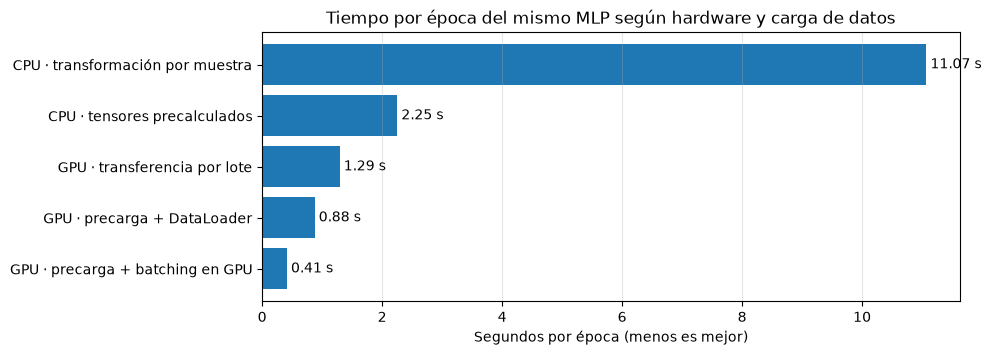

In [7]:
plt.figure(figsize=(9, 3.5))
plt.barh(bench_df.index[::-1], bench_df["s / época"][::-1], color="tab:blue")
for i, v in enumerate(bench_df["s / época"][::-1]):
    plt.text(v, i, f" {v:.2f} s", va="center")
plt.xlabel("Segundos por época (menos es mejor)")
plt.title("Tiempo por época del mismo MLP según hardware y carga de datos")
plt.grid(True, axis="x", alpha=0.3)
plt.show()

### Lectura del benchmark

- **Precalcular el preprocesado ya acelera la CPU de forma notable.** Una parte importante del tiempo "de entrenamiento en CPU" era en realidad convertir y normalizar imágenes que no cambian entre épocas.
- **Una GPU mal alimentada rinde por debajo de su capacidad.** Con datos en RAM, cada lote paga una copia CPU → GPU. Y aunque los datos estén en la GPU, `DataLoader` indexa las muestras una a una en Python y las apila, un coste que no depende del hardware.
- **Formar los lotes directamente en la GPU** elimina ambos cuellos de botella y da la mayor aceleración.
- **La ventaja "pura" de la GPU es menor que la aceleración total.** Comparando a igualdad de preprocesado (configuración 2 frente a 5), la diferencia es bastante más modesta que frente a la configuración 1. Buena parte de la aceleración total procede de haber arreglado el pipeline de datos.
- La red es pequeña (≈ 197 000 parámetros): el cálculo es tan barato que el tiempo se va en **mover y organizar datos**. Con modelos mayores la ventaja de la GPU en el cálculo sería mucho más evidente.

Las cifras concretas dependen del hardware (este cuaderno se ejecutó en una GPU de portátil), pero la jerarquía entre configuraciones es general.

## 4. Entrenamiento completo del MLP

Se entrena en la configuración más rápida disponible, con *early stopping* sobre la pérdida de validación.

In [8]:
device = gpu or cpu
x_val_d, y_val_d = x_val.to(device), y_val.to(device)
x_test_d, y_test_d = x_test.to(device), y_test.to(device)
train_loader = GPUBatchLoader(x_train.to(device), y_train.to(device), BATCH_SIZE, shuffle=True)
val_loader = GPUBatchLoader(x_val_d, y_val_d, 1024)
test_loader = GPUBatchLoader(x_test_d, y_test_d, 1024)

torch.manual_seed(SEED)
mlp = make_mlp().to(device)
print(f"Parámetros del MLP: {count_params(mlp):,}")
hist_mlp = fit(mlp, train_loader, val_loader, device)

Parámetros del MLP: 197,322


Época   1 | train loss 1.6938 | val loss 1.5664 | val acc 0.4520


Época   5 | train loss 1.3395 | val loss 1.4565 | val acc 0.4940


Época  10 | train loss 1.2100 | val loss 1.4579 | val acc 0.5026


Early stopping en la época 12: 5 épocas sin mejora.
Pesos restaurados de la época 7 | tiempo total 4.9 s


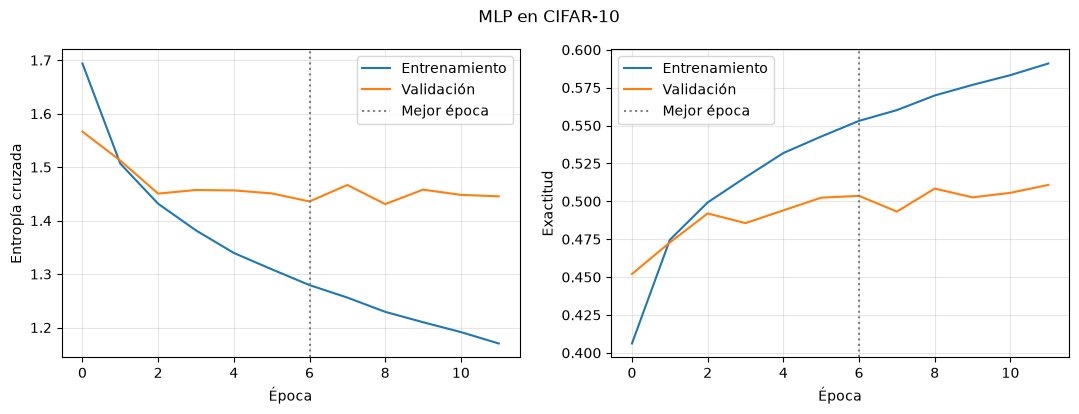

In [9]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(history["train_loss"], label="Entrenamiento")
    axes[0].plot(history["val_loss"], label="Validación")
    axes[0].set_ylabel("Entropía cruzada")
    axes[1].plot(history["train_acc"], label="Entrenamiento")
    axes[1].plot(history["val_acc"], label="Validación")
    axes[1].set_ylabel("Exactitud")
    for ax in axes:
        ax.axvline(history["best_epoch"] - 1, color="grey", linestyle=":", label="Mejor época")
        ax.set_xlabel("Época")
        ax.grid(True, alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.show()


plot_history(hist_mlp, "MLP en CIFAR-10")

Las curvas muestran un comportamiento distinto al del cuaderno 01. Aquí sí aparece **sobreajuste**: la pérdida de entrenamiento sigue bajando mientras la de validación toca fondo y empieza a subir. El *early stopping* detecta ese punto y se queda con los pesos de la mejor época.

## 5. Evaluación en test

Exactitud en test: 0.4974

              precision    recall  f1-score   support

       avión      0.578     0.506     0.540       488
   automóvil      0.561     0.605     0.582       476
      pájaro      0.458     0.345     0.394       536
        gato      0.362     0.295     0.325       512
      ciervo      0.463     0.452     0.458       471
       perro      0.354     0.387     0.370       511
        rana      0.537     0.515     0.526       495
     caballo      0.510     0.648     0.570       494
       barco      0.576     0.694     0.630       517
      camión      0.550     0.542     0.546       500

    accuracy                          0.497      5000
   macro avg      0.495     0.499     0.494      5000
weighted avg      0.494     0.497     0.493      5000



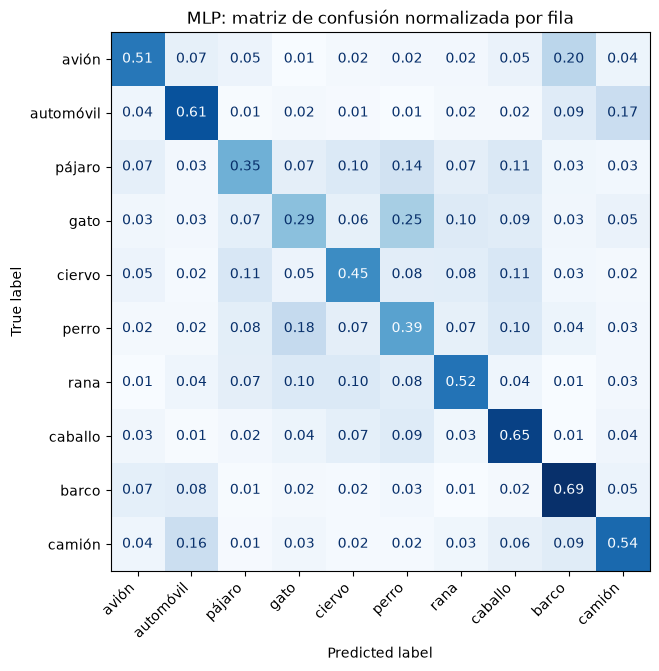

Confusiones más frecuentes (real -> predicha):
        gato -> perro      24.6%
       avión -> barco      20.3%
       perro -> gato       18.0%
   automóvil -> camión     16.6%
      camión -> automóvil  16.2%


In [10]:
def predict(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.append(model(xb).argmax(dim=1).cpu())
            labels.append(yb.cpu())
    return torch.cat(labels).numpy(), torch.cat(preds).numpy()


def evaluate(model, loader, title):
    y_true, y_pred = predict(model, loader)
    acc = (y_true == y_pred).mean()
    print(f"Exactitud en test: {acc:.4f}\n")
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

    cm = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    plt.xticks(rotation=45, ha="right")
    ax.set_title(f"{title}: matriz de confusión normalizada por fila")
    plt.show()

    off_diag = cm.copy()
    np.fill_diagonal(off_diag, 0)
    top = np.dstack(np.unravel_index(np.argsort(off_diag.ravel())[::-1][:5], cm.shape))[0]
    print("Confusiones más frecuentes (real -> predicha):")
    for i, j in top:
        print(f"  {CLASSES[i]:>10} -> {CLASSES[j]:<10} {cm[i, j]:.1%}")
    return acc


acc_mlp = evaluate(mlp, test_loader, "MLP")

### Análisis de errores

- La exactitud ronda el 50 %: cinco veces mejor que el azar (10 %), pero lejos de ser útil.
- Las confusiones se concentran entre clases **visualmente parecidas**: gato y perro, automóvil y camión, avión y barco (ambos suelen aparecer sobre fondos azules, cielo o mar). El modelo se apoya mucho en el color y la composición global de la imagen, más que en la forma del objeto.
- La causa es estructural. `Flatten` convierte la imagen en un vector de 3072 números y **destruye la estructura espacial**: para el MLP, un gato desplazado dos píxeles es una entrada completamente distinta, y cada píxel tiene sus propios pesos. No hay forma de reutilizar lo aprendido en una zona de la imagen en otra.

## 6. Extensión: el sesgo inductivo de una red convolucional

Una **red convolucional (CNN)** aplica los mismos filtros pequeños en todas las posiciones de la imagen (**compartición de pesos**) y reduce la resolución de forma progresiva (*pooling*). Así incorpora dos supuestos que se cumplen en imágenes naturales: los patrones son locales y significan lo mismo estén donde estén.

Para comprobar que la mejora viene de la arquitectura y no del tamaño, la CNN tiene **menos parámetros que el MLP**. Se entrena con exactamente el mismo pipeline.

Parámetros de la CNN: 122,570 (MLP: 197,322)


Época   1 | train loss 1.5954 | val loss 1.3361 | val acc 0.5108


Época   5 | train loss 0.8714 | val loss 0.8971 | val acc 0.6786


Época  10 | train loss 0.6247 | val loss 0.7898 | val acc 0.7316


Época  15 | train loss 0.4655 | val loss 0.8424 | val acc 0.7362


Early stopping en la época 18: 5 épocas sin mejora.
Pesos restaurados de la época 13 | tiempo total 70.2 s


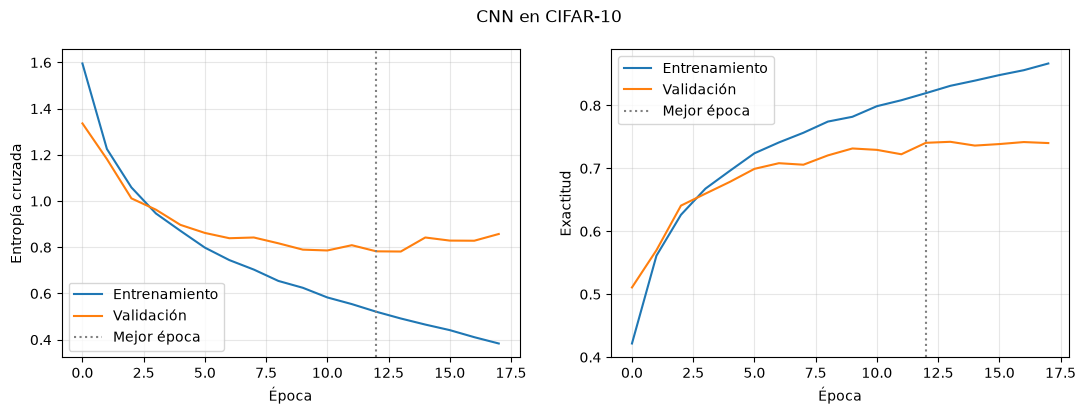

In [11]:
def make_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 32x32 -> 16x16
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16x16 -> 8x8
        nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 8x8 -> 4x4
        nn.Flatten(),
        nn.Linear(64 * 4 * 4, 64), nn.ReLU(),
        nn.Linear(64, 10),
    )


torch.manual_seed(SEED)
cnn = make_cnn().to(device)
print(f"Parámetros de la CNN: {count_params(cnn):,} (MLP: {count_params(mlp):,})")
hist_cnn = fit(cnn, train_loader, val_loader, device)
plot_history(hist_cnn, "CNN en CIFAR-10")

Exactitud en test: 0.7408

              precision    recall  f1-score   support

       avión      0.785     0.756     0.770       488
   automóvil      0.848     0.819     0.833       476
      pájaro      0.620     0.709     0.661       536
        gato      0.509     0.686     0.584       512
      ciervo      0.704     0.715     0.709       471
       perro      0.703     0.515     0.594       511
        rana      0.872     0.731     0.796       495
     caballo      0.804     0.796     0.800       494
       barco      0.889     0.870     0.880       517
      camión      0.812     0.818     0.815       500

    accuracy                          0.741      5000
   macro avg      0.755     0.742     0.744      5000
weighted avg      0.753     0.741     0.743      5000



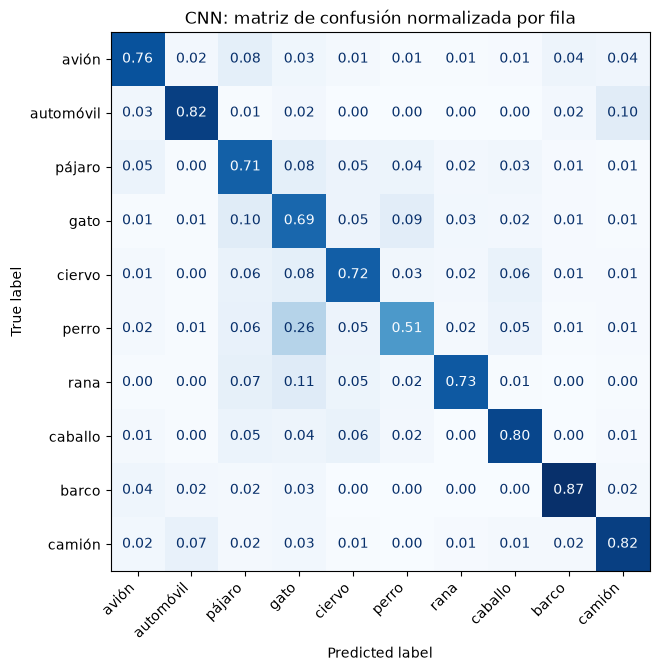

Confusiones más frecuentes (real -> predicha):
       perro -> gato       26.4%
        rana -> gato       10.5%
        gato -> pájaro     10.0%
   automóvil -> camión     9.7%
        gato -> perro      9.0%


In [12]:
acc_cnn = evaluate(cnn, test_loader, "CNN")

In [13]:
summary = pd.DataFrame([
    {"modelo": "MLP", "parámetros": count_params(mlp), "mejor época": hist_mlp["best_epoch"],
     "val acc": max(hist_mlp["val_acc"]), "test acc": acc_mlp, "tiempo (s)": hist_mlp["time"]},
    {"modelo": "CNN", "parámetros": count_params(cnn), "mejor época": hist_cnn["best_epoch"],
     "val acc": max(hist_cnn["val_acc"]), "test acc": acc_cnn, "tiempo (s)": hist_cnn["time"]},
]).set_index("modelo")
summary.round(4)

,parámetros,mejor época,val acc,test acc,tiempo (s)
modelo,,,,,
MLP,197322,7,0.5108,0.4974,4.8971
CNN,122570,13,0.7422,0.7408,70.2460


## 7. Persistencia del modelo

Un modelo guardado solo sirve si se le puede aplicar **el mismo preprocesado** que en el entrenamiento. Por eso se guardan juntos los pesos, las estadísticas de normalización y los nombres de clase. Después se recarga en un modelo nuevo y se comprueba que da el mismo resultado.

In [14]:
ckpt_path = CKPT_DIR / "cifar10_cnn.pt"
torch.save({
    "model_state": cnn.state_dict(),
    "channel_mean": channel_mean.tolist(),
    "channel_std": channel_std.tolist(),
    "classes": CLASSES,
}, ckpt_path)

checkpoint = torch.load(ckpt_path, map_location=device, weights_only=True)
restored = make_cnn().to(device)
restored.load_state_dict(checkpoint["model_state"])
y_true, y_pred = predict(restored, test_loader)
print(f"Guardado en {ckpt_path} | exactitud del modelo recargado: {(y_true == y_pred).mean():.4f}")

Guardado en ..\checkpoints\cifar10_cnn.pt | exactitud del modelo recargado: 0.7408


## 8. Conclusiones

- **Medir bien antes de concluir.** Una comparación CPU/GPU basada en tiempos totales mezcla hardware, carga de datos y número de épocas. Al separarlos, se ve que una parte grande de la diferencia se debía al **pipeline de datos** (preprocesar en cada época, copiar lotes, indexar muestra a muestra) y no a la velocidad de cálculo.
- **La GPU necesita que la alimenten bien.** Para modelos pequeños, el cuello de botella es mover datos. Precargar el conjunto en la memoria de la GPU y formar allí los lotes es lo que libera su rendimiento.
- ***Early stopping* con restauración.** Parar al estancarse la validación ahorra tiempo y, sobre todo, evita quedarse con un modelo sobreajustado.
- **La exactitud global no basta.** El informe por clase y la matriz de confusión muestran que los errores no son aleatorios: siguen similitudes visuales entre clases.
- **La arquitectura es un supuesto sobre los datos.** Con menos parámetros, la CNN supera claramente al MLP porque su estructura (filtros locales compartidos) encaja con la naturaleza de las imágenes. Mejorar el sesgo inductivo rinde más que añadir capacidad.
- **Un modelo es pesos + preprocesado.** Guardar solo el `state_dict` dejaría el modelo inservible si se pierden las estadísticas de normalización.

**Siguiente paso:** el cuaderno 04 pasa a CIFAR-100, con 100 clases organizadas en 20 superclases, y estudia si combinar un clasificador fino y uno grueso mejora las predicciones.